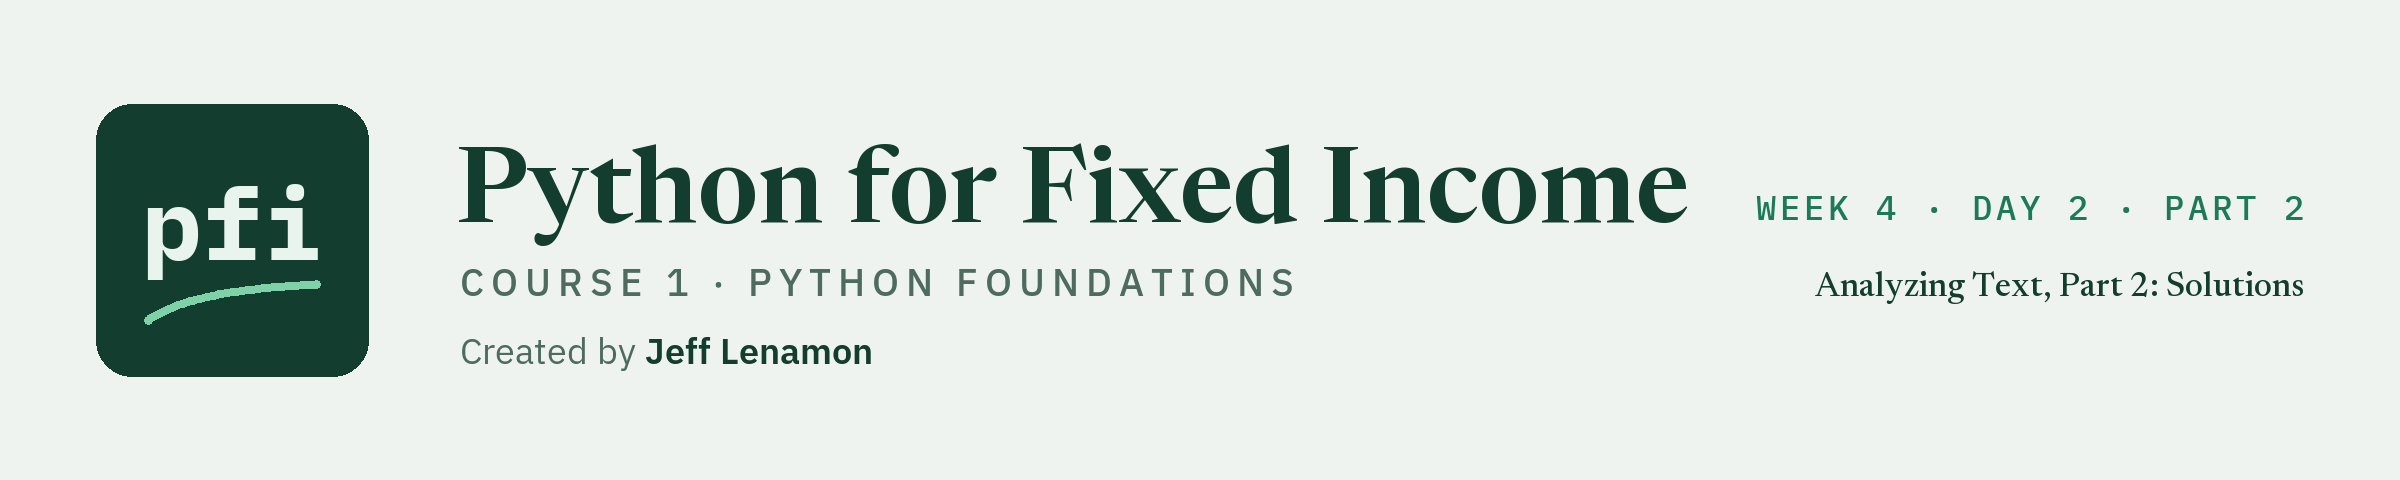

# Analyzing Text, Part 2: Solutions

Week 4, Day 2, Part 2. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week4/day2_part2/17_part2_analyzing_text_solutions.ipynb)

The statements are public text from the Board of Governors of the Federal Reserve System, retrieved 2026-10-03; the teaching notebook gives the source and reuse terms.

## Exercises

Each exercise is answered in full, and the check cell after it prints the result.
Run the next two cells first: one defines `check`, the other loads the statements, `clean()`, and `stop_words`.

In [1]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [2]:
import os
import re
from collections import Counter

import matplotlib.pyplot as plt
import nltk
import pandas as pd

# a fresh copy of the statements; in Colab, from GitHub
if os.path.exists('../../../data/fomc_statements.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
statements = pd.read_csv(data_folder + 'fomc_statements.csv')
# the statement of 2022-09-21, for Exercise 1
other = statements.loc[statements['date'] == '2022-09-21', 'text'].iloc[0]


def clean(text):
    # the lesson's four steps
    text = re.sub(r'[^a-z\s]', ' ', text.lower())
    text = re.sub(r'\s+', ' ', text).strip()
    return text.split(' ')


nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords

stop_words = stopwords.words('english')
print(statements.shape, len(stop_words))

(46, 3) 198


### Exercise 1

Q. Clean `other`. Store its tokens' count in **ex1_tokens**, the count after nltk's stopwords in **ex1_kept**, and the most common kept token in **ex1_top**.

In [3]:
tokens = clean(other)
ex1_tokens = len(tokens)
# keep the tokens that are not stopwords
kept = [token for token in tokens if token not in stop_words]
ex1_kept = len(kept)
# most_common(1) is a list holding one (token, count) pair: [0][0] is the token
counts = Counter(kept)
ex1_top = counts.most_common(1)[0][0]
print(ex1_tokens, ex1_kept, counts.most_common(4))

315 201 [('committee', 9), ('inflation', 7), ('rate', 3), ('economic', 3)]


315 tokens, 201 after stopword removal.
The most common kept token on 2022-09-21 is `committee`, 9 times, then `inflation` 7.

In [4]:
check('Exercise 1 tokens', ex1_tokens, 315)
check('Exercise 1 kept', ex1_kept, 201)
check('Exercise 1 most common', ex1_top, 'committee')

Exercise 1 tokens: correct
Exercise 1 kept: correct
Exercise 1 most common: correct


### Exercise 2

Q. Add `words` and `year` columns. Store the year with the highest mean word count in **ex2_year**, that mean to 1 decimal place in **ex2_mean**, and the statements holding the whole word `uncertain` in **ex2_uncertain**. Draw the means as bars.

In [5]:
statements['words'] = statements['text'].str.split().str.len()
statements['year'] = pd.to_datetime(statements['date'], format='%Y-%m-%d').dt.year
by_year = statements.groupby('year')['words'].mean().round(1)
# idxmax() gives the label of the highest; int() and float() make plain numbers
ex2_year = int(by_year.idxmax())
ex2_mean = float(by_year.max())
# \b on each side, so uncertainty is not counted
lower_text = statements['text'].str.lower()
ex2_uncertain = int(lower_text.str.contains(r'\buncertain\b').sum())
print(ex2_year, ex2_mean, ex2_uncertain, lower_text.str.contains('uncertain').sum())

2021 505.5 19 32


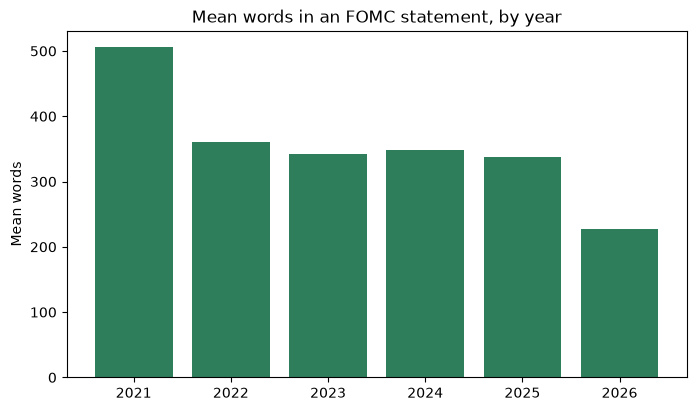

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
# the house green, as in the lesson's charts
ax.bar(by_year.index, by_year, color='#2E7D5B')
ax.set_title('Mean words in an FOMC statement, by year')
ax.set_ylabel('Mean words')
plt.show()

2021 has the highest mean, 505.5 words; the other years run 228.0 to 361.1.
19 statements hold the whole word `uncertain`; without `\b` it is 32, since the letters sit inside `uncertainty`.

In [7]:
check('Exercise 2 year', ex2_year, 2021)
check('Exercise 2 mean words', ex2_mean, 505.5)
check('Exercise 2 uncertain', ex2_uncertain, 19)

Exercise 2 year: correct
Exercise 2 mean words: correct
Exercise 2 uncertain: correct


### Exercise 3

Q. Build the document-term table of every kept token. Store its number of columns in **ex3_vocabulary** and the percent of kept tokens the top 20 cover, to 1 decimal place, in **ex3_share**.

In [8]:
# each statement's kept tokens, then a Counter of each
kept = statements['text'].apply(clean).apply(
    lambda tokens: [token for token in tokens if token not in stop_words])
counters = kept.apply(Counter)
# one column per different token, 0 where a statement lacks it
table = pd.DataFrame(list(counters)).fillna(0).astype(int)
ex3_vocabulary = table.shape[1]
totals = table.sum()
ex3_share = round(totals.nlargest(20).sum() / totals.sum() * 100, 1)
print(table.shape, totals.nlargest(20).sum(), totals.sum(), ex3_share)

(46, 507) 3066 10204 30.0


507 different tokens; the 20 most common cover 3,066 of the 10,204 kept tokens, 30.0 percent.

**Excel side by side.** The table is a pivot: statement in Rows, token in Columns, count in Values.

In [9]:
check('Exercise 3 different tokens', ex3_vocabulary, 507)
check('Exercise 3 share covered', ex3_share, 30.0)

Exercise 3 different tokens: correct
Exercise 3 share covered: correct


### Exercise 4: AI check

Q. The lesson found a range in every statement. Fix the AI's code so **ex4_statements** is right, then store the first statement's range, as text, in **ex4_first**.

The AI's pattern `\d+ to \d+ percent` allows only digits on each side of `to`, so it misses every figure with a slash or a hyphen, and its 6 matches are worse than a miss: `4 to 1 percent` is the tail of `3/4` and the start of `1`.
The fix is the lesson's widened class; the check was the count, 46 due.

In [10]:
# a figure may hold digits, slashes, and either hyphen
pattern = r'[\d/\u2011-]+ to [\d/\u2011-]+ percent'
found = statements['text'].str.findall(pattern)
ex4_statements = int((found.str.len() > 0).sum())
ex4_first = found.iloc[0][0]
print(ex4_statements, ex4_first)

46 0 to 1/4 percent


In [11]:
check('Exercise 4 statements with a range', ex4_statements, 46)
check('Exercise 4 first range', ex4_first, '0 to 1/4 percent')

Exercise 4 statements with a range: correct
Exercise 4 first range: correct


### Exercise 5: AI check

Q. The AI's code printed 4 and 188 for the word rate. Fix it so **ex5_one** and **ex5_total** count the whole word.

`count('rate')` counts the four letters wherever they fall.
Which words did it count?

In [12]:
# every word holding the letters rate, across all statements
containing = Counter()
for text in statements['text']:
    containing.update(re.findall(r'\w*rate\w*', text))
print(containing)
# the fix: \b on each side asks for the whole word
one = statements.loc[statements['date'] == '2023-11-01', 'text'].iloc[0]
ex5_one = len(re.findall(r'\brate\b', one))
ex5_total = int(statements['text'].str.count(r'\brate\b').sum())
print(ex5_one, ex5_total)

Counter({'rate': 163, 'moderately': 14, 'moderated': 7, 'moderate': 3, 'concentrated': 1})
3 163


The 188 is 163 for `rate` and 25 for words that hold it: `moderately` 14, `moderated` 7, `moderate` 3, `concentrated` 1.
With `\b`, 3 and 163, the lesson's numbers: no error warned, only a count worked another way.

In [13]:
check('Exercise 5 one statement', ex5_one, 3)
check('Exercise 5 all statements', ex5_total, 163)

Exercise 5 one statement: correct
Exercise 5 all statements: correct
